# Preparação do dataset

Cada timestamp é uma coleta do medidor da linha selecionada. O delta representa o volume enviado **a partir dessa coleta até a próxima**, quando a distância é de 10 minutos ± 40 segundos. Não há interpolação, conversão de unidade ou cálculo de vazão.

Os sensores são pareados pela última observação até a coleta, com tolerância explícita. A válvula representa o estado observado em t, não uma classificação da janela inteira. Registros adicionais de mudança da válvula são preservados.


In [2]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Localiza o projeto mesmo ao abrir o notebook pela pasta notebooks.
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "data" / "raw").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


## 1. Parâmetros



In [3]:
ANO = "2024"
LINHA = 3
DISPOSITIVO_SOIL = "2f2ba968948ac82e9517eddb42fc1043d211d6da9f0725cd47ce2fb995701b92"

PASSO_MS = 10 * 60_000
DESVIO_PASSO_MS = 20_000
TOL_VALVE_MS = 10 * 60_000
TOL_SOIL_MS = 10 * 60_000 + 10_000
TOL_ENV_MS = 10 * 60_000 + 20_000
PASTA_DADOS = ROOT / "data" / "raw" / ANO

ENTRADA_MEDIDOR = ROOT / "data" / "raw" / ANO / f"water_meter{ANO}.csv"
ENTRADA_VALVE = ROOT / "data" / "raw" / ANO / f"valve_controller{ANO}.csv"
ENTRADA_ENVIRONMENTAL = ROOT / "data" / "raw" / ANO / f"environmental{ANO}.csv"
ENTRADA_INDICADOR = ROOT / "data" / "raw" / ANO / f"indicators{ANO}.csv"
ENTRADA_SOIL = ROOT / "data" / "raw" / ANO / f"soil{ANO}.csv"

COLUMNS_VALVE = {"ts_generation", "line", "valve_state"}
COLUMNS_MEDIDOR = {"ts_generation", "line", "current_volume"}
COLUMNS_ENV = {"ts_generation", "temperature", "humidity"}
COLUMNS_GDD = {"ts_generation", "gdd"}
COLUMNS_SOIL = {"ts_generation", "line", "humidity", "generated_by"}

FILTER_LINE = {"line": LINHA, "drop": ["line"]}
FILTER_SOIL = {"line": LINHA, "generated_by": DISPOSITIVO_SOIL,  "drop": ["line", "generated_by"]} # filtrando por dispositivo 15cm


## 2. Leitura e seleção dos sensores


In [4]:
def carregar(caminho, columns, filter:dict = None):
    df = pd.read_csv(caminho, sep=',', header=0, usecols=columns)

    # sla se eu quiser aplicar algum filtro
    if filter:
        for key in filter:
            if key != "drop":
                df = df.loc[df[key] == filter[key]]
        if "drop" in filter: df = df.drop(columns=filter["drop"])

    #ordenação
    df = df.sort_values(by="ts_generation", ascending=True)
    # só pa ver :)
    df["date"] = pd.to_datetime(df["ts_generation"], unit="ms")
    # amostragem_ts(df)
    return df

registros_medidor = carregar(ENTRADA_MEDIDOR, columns=COLUMNS_MEDIDOR, filter=FILTER_LINE)
registros_valve = carregar(ENTRADA_VALVE, filter=FILTER_LINE, columns=COLUMNS_VALVE)
registros_env = carregar(ENTRADA_ENVIRONMENTAL, columns=COLUMNS_ENV)
registros_gdd = carregar(ENTRADA_INDICADOR, columns=COLUMNS_GDD)
registros_soil = carregar(ENTRADA_SOIL, filter=FILTER_SOIL, columns=COLUMNS_SOIL)

registros_env = registros_env.rename(columns={"temperature":"temperature_env","humidity": "humidity_env"})
registros_soil = registros_soil.rename(columns={"humidity": "humidity_soil"})
assert registros_valve.valve_state.isin([0, 1]).all()

display(pd.Series({"medidor": len(registros_medidor), "válvula": len(registros_valve),
                   "solo": len(registros_soil), "ambiente": len(registros_env)}, name="leituras").to_frame())

,leituras
medidor,13186
válvula,11658
solo,13334
ambiente,9327


## 3. Volume na janela seguinte

O delta em t é V(próxima coleta) − V(t). Só é aceito se a próxima coleta estiver aproximadamente dez minutos adiante e o contador não cair.

A última coleta não tem delta conhecido. 

In [5]:
dataset = registros_medidor.copy()
duracao_ms = dataset.ts_generation.shift(-1) - dataset.ts_generation
delta = dataset.current_volume.shift(-1) - dataset.current_volume
janela_valida = duracao_ms.between(PASSO_MS - DESVIO_PASSO_MS, PASSO_MS + DESVIO_PASSO_MS)
dataset["delta_volume"] = delta.where(janela_valida & delta.ge(0))
# O contador bruto permanece em registros_medidor para consulta.
dataset = dataset.drop(columns="current_volume")


## 4. Pareamento temporal

O merge_asof não exige horários idênticos: apenas observações anteriores ou exatas, sem trazer valores futuros. 

Os horários de origem ficam em pareamentos para conferir as diferenças -> não entram no dataset final.

In [6]:
pareamentos = dataset[["ts_generation", "delta_volume"]].copy()
# Seleciona apenas as medições: date e outras colunas do carregamento não entram nos merges.
for nome, sensor, tolerancia in [
    ("valve", registros_valve[["ts_generation", "valve_state"]], TOL_VALVE_MS),
    ("soil", registros_soil[["ts_generation", "humidity_soil"]], TOL_SOIL_MS),
    ("env", registros_env[["ts_generation", "temperature_env", "humidity_env"]], TOL_ENV_MS),
]:
    pareamentos = pd.merge_asof(
        pareamentos, sensor.rename(columns={"ts_generation": f"ts_{nome}"}),
        left_on="ts_generation", right_on=f"ts_{nome}",
        direction="backward", tolerance=tolerancia,
    )

colunas = ["ts_generation", "valve_state", "delta_volume",
           "humidity_soil", "temperature_env", "humidity_env"]
dataset = pareamentos[colunas].copy()
dataset.insert(1, "date", pd.to_datetime(dataset.ts_generation, unit="ms", utc=True))

def resumo_pareamento(nome):
    atraso_s = (pareamentos.ts_generation - pareamentos[f"ts_{nome}"]) / 1000
    return {"sensor": nome, "sem_par": atraso_s.isna().sum(),
            "atraso_mediano_s": atraso_s.median(), "atraso_maximo_s": atraso_s.max()}

display(pd.DataFrame([resumo_pareamento(n) for n in ["valve", "soil", "env"]]))
display(dataset.isna().sum().rename("ausentes").to_frame())
display(dataset.head())


,sensor,sem_par,atraso_mediano_s,atraso_maximo_s
0,valve,1769,238.0080,599.993
1,soil,370,294.8725,604.873
2,env,3862,233.1525,613.461


,ausentes
ts_generation,0
date,0
valve_state,1769
delta_volume,163
humidity_soil,393
temperature_env,3862
humidity_env,3864


,ts_generation,date,valve_state,delta_volume,humidity_soil,temperature_env,humidity_env
0,1718006140606,2024-06-10 07:55:40.606000+00:00,NaN,NaN,NaN,NaN,NaN
1,1718015141086,2024-06-10 10:25:41.086000+00:00,NaN,NaN,NaN,NaN,NaN
2,1718024142267,2024-06-10 12:55:42.267000+00:00,NaN,NaN,NaN,NaN,NaN
3,1718033142907,2024-06-10 15:25:42.907000+00:00,NaN,NaN,NaN,NaN,NaN
4,1718042143998,2024-06-10 17:55:43.998000+00:00,NaN,0.0,NaN,NaN,NaN


In [7]:
# Umidade ao fim da mesma janela usada no delta, antes de remover ausências.
# Delta ausente significa que não há uma janela de dez minutos utilizável.
dataset["humidity_soil_fim"] = dataset.humidity_soil.shift(-1).where(dataset.delta_volume.notna())

# Mantém todas as coletas; o script do ARX trata as ausências e os lags.
PASTA_M3 = ROOT / "data" / "m3"
PASTA_M3.mkdir(parents=True, exist_ok=True)
dataset.to_csv(PASTA_M3 / f"dataset_{ANO}_linha_{LINHA}.csv", index=False)
dataset


,ts_generation,date,valve_state,delta_volume,humidity_soil,temperature_env,humidity_env,humidity_soil_fim
0,1718006140606,2024-06-10 07:55:40.606000+00:00,NaN,NaN,NaN,NaN,NaN,NaN
1,1718015141086,2024-06-10 10:25:41.086000+00:00,NaN,NaN,NaN,NaN,NaN,NaN
2,1718024142267,2024-06-10 12:55:42.267000+00:00,NaN,NaN,NaN,NaN,NaN,NaN
3,1718033142907,2024-06-10 15:25:42.907000+00:00,NaN,NaN,NaN,NaN,NaN,NaN
4,1718042143998,2024-06-10 17:55:43.998000+00:00,NaN,0.0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
13181,1727431032467,2024-09-27 09:57:12.467000+00:00,NaN,NaN,NaN,NaN,NaN,NaN
13182,1727517436166,2024-09-28 09:57:16.166000+00:00,NaN,NaN,NaN,NaN,NaN,NaN
13183,1727603839329,2024-09-29 09:57:19.329000+00:00,NaN,NaN,NaN,NaN,NaN,NaN
13184,1727690242470,2024-09-30 09:57:22.470000+00:00,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Lags e tabela para as análises

Os lags são calculados antes de remover ausências -> a linha anterior não vira automaticamente um lag de dez minutos após uma lacuna.

* `dataset` preserva todas as coletas e suas ausências. 

* `df_aut` contém as linhas completas para as análises existentes. 

* `delta_volume` olha o futuro: se for usado como alvo de previsão, não deve entrar também como variável de entrada.


In [8]:
df_aut = dataset.copy()
passo_anterior = df_aut.ts_generation.diff()
regular = passo_anterior.between(PASSO_MS - DESVIO_PASSO_MS, PASSO_MS + DESVIO_PASSO_MS)
for lag in [1, 2]:
    sequencia_regular = regular.rolling(lag, min_periods=lag).sum().eq(lag)
    df_aut[f"humidity_soil_lag_{lag}"] = df_aut.humidity_soil.shift(lag).where(sequencia_regular)

# Mantém os índices originais para rastrear cada coleta na tabela de pareamentos.
df_aut = df_aut.dropna().copy()
for lag in [1, 2]:
    df_aut[f"ts_lag_{lag}"] = dataset.ts_generation.shift(lag).loc[df_aut.index]
    df_aut[f"valve_state_lag_{lag}"] = dataset.valve_state.shift(lag).loc[df_aut.index]
print(f"Coletas: {len(dataset):,}; completas com lags: {len(df_aut):,}; removidas: {len(dataset) - len(df_aut):,}")
display(df_aut.head())


Coletas: 13,186; completas com lags: 8,549; removidas: 4,637


,ts_generation,date,valve_state,delta_volume,humidity_soil,temperature_env,humidity_env,humidity_soil_fim,humidity_soil_lag_1,humidity_soil_lag_2,ts_lag_1,valve_state_lag_1,ts_lag_2,valve_state_lag_2
182,1718150770905,2024-06-12 00:06:10.905000+00:00,0.0,0.0,0.0,17.6,81.0,0.0,0.0,0.0,1.718150e+12,NaN,1.718150e+12,NaN
184,1718151970908,2024-06-12 00:26:10.908000+00:00,0.0,0.0,0.0,17.3,90.0,0.0,0.0,0.0,1.718151e+12,NaN,1.718151e+12,0.0
186,1718153172020,2024-06-12 00:46:12.020000+00:00,0.0,0.0,0.0,17.1,91.0,0.0,0.0,0.0,1.718153e+12,NaN,1.718152e+12,0.0
188,1718154373340,2024-06-12 01:06:13.340000+00:00,0.0,0.0,0.0,16.7,90.0,0.0,0.0,0.0,1.718154e+12,NaN,1.718153e+12,0.0
190,1718155572615,2024-06-12 01:26:12.615000+00:00,0.0,0.0,0.0,16.4,96.0,0.0,0.0,0.0,1.718155e+12,NaN,1.718154e+12,0.0


## Dataset enriquecido para comparar o ARX

Conjunto separado para o experimento, sem modificar dataset e df_aut. Inclui pressão atmosférica, CO₂, condutividade do mesmo sensor de solo e GDD anterior (atrasado um dia para não usar um indicador diário calculado com informação futura).


In [9]:
dataset_enriquecido = dataset.copy()
ambiente_extra = pd.read_csv(ENTRADA_ENVIRONMENTAL, usecols=["ts_generation", "pressure", "co2"])
solo_extra = pd.read_csv(ENTRADA_SOIL, usecols=["ts_generation", "line", "generated_by", "electrical_conductivity"])
solo_extra = solo_extra.loc[solo_extra.line.eq(LINHA) & solo_extra.generated_by.eq(DISPOSITIVO_SOIL), ["ts_generation", "electrical_conductivity"]]
gdd_extra = registros_gdd[["ts_generation", "gdd"]].copy()
# Conservador: disponibiliza cada indicador apenas 24 horas após seu timestamp.
gdd_extra["ts_generation"] += 24 * 60 * 60_000
for dados_extra, tolerancia in [(ambiente_extra, TOL_ENV_MS), (solo_extra, TOL_SOIL_MS), (gdd_extra, 48 * 60 * 60_000)]:
    dataset_enriquecido = pd.merge_asof(dataset_enriquecido.sort_values("ts_generation"),
        dados_extra.sort_values("ts_generation"), on="ts_generation",
        direction="backward", tolerance=tolerancia)
dataset_enriquecido.to_csv(PASTA_M3 / f"dataset_enriquecido_{ANO}_linha_{LINHA}.csv", index=False)
display(dataset_enriquecido[["gdd", "pressure", "co2", "electrical_conductivity"]].isna().sum().to_frame("ausentes"))


,ausentes
gdd,3213
pressure,7428
co2,3862
electrical_conductivity,372


## Analises

entradas: erro = 27% [fonte:baseline] - h(t); dh_20min = (h(t) - h(t-2))/20

saídas: tempo de irrigação

ideia:
* erro: excesso, transicao, deficit
* dh_20min: diminuindo, estavel, aumentando
* ti: desligado, curto, longo

### Duração dos eventos de irrigação

Calculada nos registros originais da válvula, antes dos pareamentos e da remoção de ausências. Somente pares completos de abertura e fechamento no mesmo trecho contínuo são usados; lacunas maiores que o passo tolerado interrompem o evento.


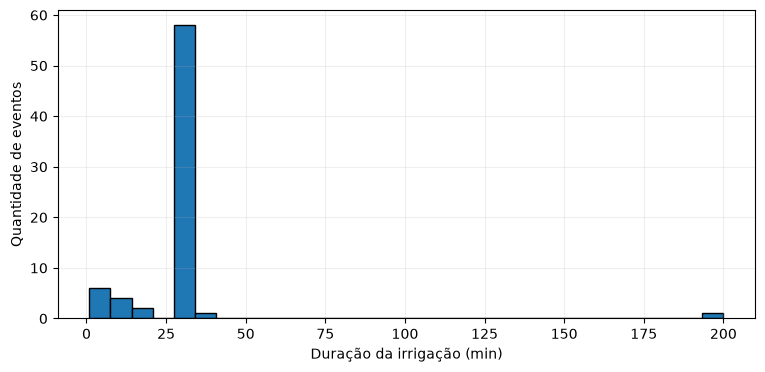

In [10]:
# A duração depende somente dos registros originais da válvula.
# Não usar df_aut: merges e dropna podem apagar desligamentos.
base_valve = registros_valve.sort_values("ts_generation").copy()

# Uma lacuna maior que o passo tolerado interrompe a observação do evento.
# Não associar uma abertura ao fechamento de outro trecho da série.
base_valve["trecho"] = (
    base_valve.ts_generation.diff().gt(PASSO_MS + DESVIO_PASSO_MS)
).cumsum()
estado_anterior = base_valve.groupby("trecho")["valve_state"].shift()
transicoes = base_valve.loc[
    estado_anterior.notna() & base_valve.valve_state.ne(estado_anterior),
    ["ts_generation", "valve_state", "trecho"],
].copy()
proxima = transicoes.shift(-1)
completos = (
    transicoes.valve_state.eq(1)
    & proxima.valve_state.eq(0)
    & transicoes.trecho.eq(proxima.trecho)
)
eventos_irrigacao = transicoes.loc[completos, ["ts_generation"]].rename(
    columns={"ts_generation": "inicio"}
)
eventos_irrigacao["fim"] = proxima.loc[completos, "ts_generation"].astype("int64")
eventos_irrigacao["duracao_min"] = (
    eventos_irrigacao.fim - eventos_irrigacao.inicio
) / 60_000

duracoes = eventos_irrigacao["duracao_min"].rename("Duração (min)")
# display(duracoes.describe(percentiles=[.05, .25, .50, .75, .95]).to_frame())

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(duracoes, bins=30, edgecolor="black")
ax.set_xlabel("Duração da irrigação (min)")
ax.set_ylabel("Quantidade de eventos")
ax.grid(alpha=0.2)
plt.show()


### analise de antes e apos evento de irrigação

In [11]:
base = df_aut.sort_values("ts_generation").copy()

base["dh_20min"] = (
    base["humidity_soil"]
    - base["humidity_soil_lag_2"]
) / 20  # 20 garantido por causa do filtro

# Identifica quando a válvula passa de ligada (1) para desligada (0)
desligamentos = transicoes.loc[
    transicoes.valve_state.eq(0), ["ts_generation"]
].rename(columns={"ts_generation": "ts_fim"}).sort_values("ts_fim")
base["fim_irrigacao"] = base["ts_generation"].isin(desligamentos["ts_fim"])

# Tempo desde o último desligamento
base = pd.merge_asof(
    base, desligamentos, left_on="ts_generation", right_on="ts_fim",
    direction="backward",
).set_axis(base.index)

base["min_apos_fim"] = (
    base["ts_generation"] - base["ts_fim"]
) / 60_000

# Mantém somente intervalos válidos para dh_20min
base["intervalo_min"] = (
    base["ts_generation"] - base["ts_lag_2"]
) / 60_000

validos = base["intervalo_min"].between(19, 21)

# Secagem: válvula desligada há mais de 60 minutos
secagem = (
    validos
    & base["valve_state"].eq(0)
    & base["valve_state_lag_1"].eq(0)
    & base["valve_state_lag_2"].eq(0)
    & (
        base["min_apos_fim"].gt(60)
        | base["min_apos_fim"].isna()
    )
)

# Pós-irrigação: janela de 20 a 60 minutos após o desligamento
pos_irrigacao = (
    validos
    & base["valve_state"].eq(0)
    & base["min_apos_fim"].between(20, 60)
)

comparacao = pd.DataFrame({
    "Secagem": base.loc[secagem, "dh_20min"].describe(
        percentiles=[.05, .25, .50, .75, .95]
    ),
    "Pós-irrigação": base.loc[pos_irrigacao, "dh_20min"].describe(
        percentiles=[.05, .25, .50, .75, .95]
    )
})

display(comparacao.style.format("{:.5f}"))

,Secagem,Pós-irrigação
count,8069.00000,149.00000
mean,-0.00233,-0.02421
std,0.01794,0.06108
min,-0.18050,-0.09400
5%,-0.01650,-0.06850
25%,-0.00350,-0.05350
50%,0.00000,-0.04250
75%,0.00000,-0.02050
95%,0.00300,0.12910
max,0.87200,0.28750


bem distindos o dh_20min comparando um periodo de seca com um apos um evento de irrigação

In [12]:
# tempo ate proxima amostra -
eventos = pd.merge_asof(
    desligamentos,
    base[["ts_generation"]],
    left_on="ts_fim", right_on="ts_generation",
    direction="forward", allow_exact_matches=False,
)

eventos["min_proxima_amostra"] = (
    eventos["ts_generation"] - eventos["ts_fim"]
) / 60_000

display(
    eventos["min_proxima_amostra"]
    .describe(percentiles=[.05, .25, .50, .75, .95])
    .to_frame("Minutos até próxima amostra")
    .style.format("{:.2f}")
)

,Minutos até próxima amostra
count,74.00
mean,2648.49
std,6161.64
min,1.93
5%,2.76
25%,4.70
50%,6.06
75%,31.08
95%,19706.48
max,21622.39


### analises da umidade e dos intervalos -> para possivel filtro


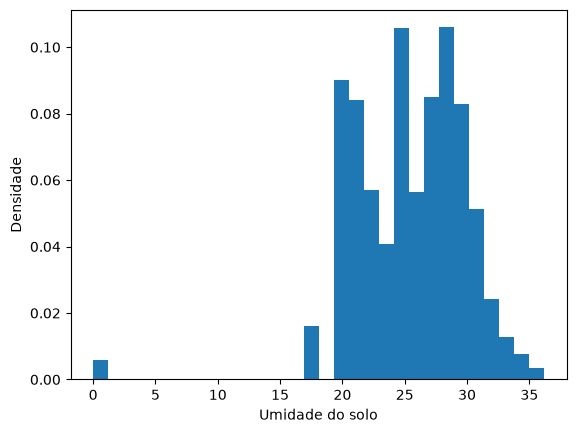

Avaliando a umidade do solo: 
 count    8549.000000
mean       25.393785
std         4.505799
min         0.000000
5%         19.500000
10%        20.170000
25%        21.930000
50%        25.470000
75%        28.600000
90%        30.410000
95%        31.680000
max        36.180000
Name: humidity_soil, dtype: float64
Amplitude: 36.18


In [13]:
import matplotlib.pyplot as plt

h = df_aut["humidity_soil"]


fig, ax = plt.subplots()
ax.hist(h, bins=30, density=True)
ax.set_xlabel("Umidade do solo")
ax.set_ylabel("Densidade")
plt.show()

print("Avaliando a umidade do solo: \n", h.describe(
    percentiles=[.05, .10, .25, .50, .75, .90, .95]
))
print("Amplitude:", h.max() - h.min())

In [14]:
# Analisando amostragem para verifciar se há concentração em 20 minutos

df_check = df_aut.sort_values("ts_generation").copy()

df_check["intervalo_min"] = (
    df_check["ts_generation"]
    - df_check["ts_lag_2"]
) / 60_000

display(
    df_check["intervalo_min"].describe(
        percentiles=[.05, .25, .50, .75, .95]
    )
)

# vendo intervalos fora de 20 minutos
intervalo = df_check["intervalo_min"]

print("Intervalos fora de 19–21 min:",
      (~intervalo.between(19, 21) & intervalo.notna()).sum())

print("Percentual:",
      (~intervalo.between(19, 21) & intervalo.notna()).mean() * 100)

count    8549.000000
mean       20.001447
std         0.013829
min        19.891567
5%         19.978167
25%        19.991650
50%        20.001383
75%        20.011400
95%        20.024527
max        20.101417
Name: intervalo_min, dtype: float64

Intervalos fora de 19–21 min: 0
Percentual: 0.0


pela mediana e p5 a p95 -> boa regularidade;

min e max -> sem lacunas;

In [15]:
# filtro em 95%
# Intervalos regulares

mask = df_check["intervalo_min"].between(19, 21)

# Dados específicos para análise temporal
df_dinamica = df_check.loc[mask].copy()

# Verificar os registros restantes
print("Observações:", len(df_dinamica))
print("Percentual mantido:", f"{mask.mean():.2%}")

Observações: 8549
Percentual mantido: 100.00%


### definição de universos e funções de pertinencia

In [16]:
# Referência do baseline
setpoint = 27

# Erro de controle
df_dinamica["erro"] = setpoint - df_dinamica["humidity_soil"]
e = df_dinamica["erro"]

# Variação média da umidade por minuto
df_dinamica["dh_20min"] = (
    df_dinamica["humidity_soil"]
    - df_dinamica["humidity_soil_lag_2"]
) / 20  # 20 garantido por causa do filtro
d = df_dinamica["dh_20min"]

# o erro não precisaria do filtro, porque observa o inst atual, mas para facilitar a metodologia, vou manter em ambos, já que o dh20 precisa
# Preserva a tabela final, incluindo erro e tendência usados pelo fuzzy.
CAMINHO_DINAMICA = PASTA_M3 / f"df_dinamica_{ANO}_linha_{LINHA}.csv"
df_dinamica.to_csv(CAMINHO_DINAMICA, index=False)


#### analise do erro

* ver a distribuição do erro e em relação aos limiares de 24% e 27% do baseline

,Erro
count,8549.0000
mean,1.6062
std,4.5058
min,-9.1800
5%,-4.6800
10%,-3.4100
25%,-1.6000
50%,1.5300
75%,5.0700
90%,6.8300


Erro = 0: quando h(t) é 27%, enquanto erro = 3: quando h(t) é 24%
Os dois limiares do baseline


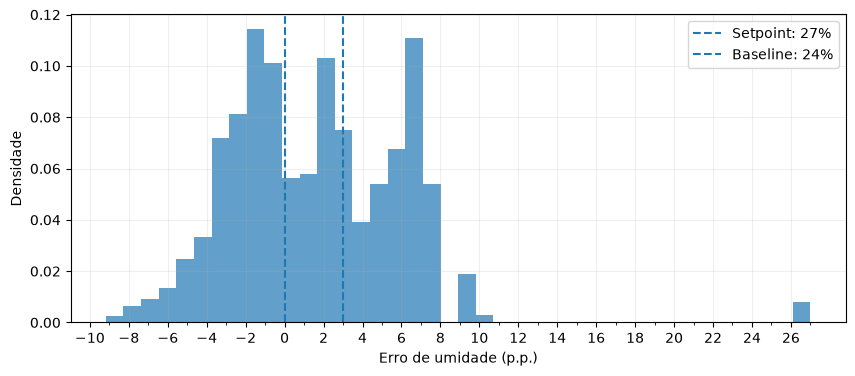

In [34]:
# descritivas do erro
percentis = [.05, .10, .25, .50, .75, .90, .95]

display(
    e.describe(percentiles=percentis)
    .to_frame("Erro")
    .style.format("{:.4f}")
)

# distribuição do erro
print("Erro = 0: quando h(t) é 27%, enquanto erro = 3: quando h(t) é 24%", "Os dois limiares do baseline", sep='\n')
fig, ax = plt.subplots(figsize=(10, 4))

ax.hist(e, bins=40, density=True, alpha=0.7)

ax.axvline(0, linestyle="--", label="Setpoint: 27%")
ax.axvline(3, linestyle="--", label="Baseline: 24%")

ax.set_xticks(np.arange(np.floor(e.min()), np.ceil(e.max()) + 1, 2))
ax.set_xticks(np.arange(np.floor(e.min()), np.ceil(e.max()) + 1, 1), minor=True)
ax.set_xlabel("Erro de umidade (p.p.)")
ax.set_ylabel("Densidade")
ax.legend()
ax.grid(alpha=0.2)

plt.show()

* universo aproximado [−10, 27]
* parece três modass

In [18]:
# ver o quanto do histórico ficou em cada faixa operacional do baseline 
regioes = pd.DataFrame({
    "Região": [
        "Acima de 27%",
        "Entre 24% e 27%",
        "Abaixo de 24%"
    ],
    "Quantidade": [
        (e < 0).sum(),
        ((e >= 0) & (e <= 3)).sum(),
        (e > 3).sum()
    ]
})

regioes["Percentual"] = regioes["Quantidade"] / len(e)

display(
    regioes.style.format({
        "Quantidade": "{:,.0f}",
        "Percentual": "{:.1%}"
    }).hide(axis="index")
)

Região,Quantidade,Percentual
Acima de 27%,"3,695",43.2%
Entre 24% e 27%,"2,001",23.4%
Abaixo de 24%,"2,853",33.4%


* erro +10 ou +20, é déficit significativamente igual -> pertinencia de um deficit não reduz, pq tá longe da moda -> trapézio

em relação a ref:
* e < 0: acima de 27% -> excesso de umidade
* 0 <= e <= 3: entre 24 e 27% -> mantem o ultimo estado da valvula  
* e > 3: a baixo de 24% -> deficit q aciona irrigação no baseline

trapezoide em todos

#### analise do df_20min

* ver a escala das variações e como seria umidade diminuindo, estável ou aumentando aqui


Descrição de dh_20min:


,dh_20min
count,8549.00000
mean,0.00005
std,0.03675
min,-0.18050
5%,-0.02000
10%,-0.01150
25%,-0.00350
50%,0.00000
75%,0.00000
90%,0.00150


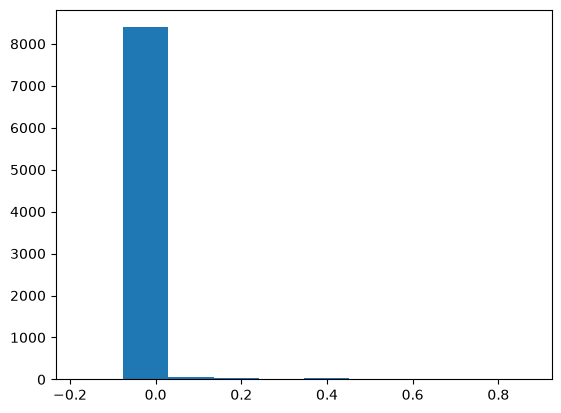

In [19]:
# olhando distribuição de df_20min
print("\nDescrição de dh_20min:")
display(
    d.describe(percentiles=percentis)
    .to_frame("dh_20min")
    .style.format("{:.5f}")
)

# fig, ax = plt.subplots(figsize=(10, 4))

# ax.hist(d, bins=100, density=True)

# ax.set_xlabel("Variação da umidade (p.p./min)")
# ax.set_ylabel("Densidade")
# ax.grid(alpha=0.2)

# plt.show()

# print(d.describe(
#     percentiles=[.05, .10, .25, .50, .75, .90, .95]
# ))

plt.hist(d)
plt.show()

maior parte das variações é pequena, com quedas mais frequentes que aumentos

In [20]:
# analise em cima dos 3 grupos para dh_20min
print("\nfrequencia de dh_20min:")
print("Quedas:", (d < 0).mean()*100)
print("Estáveis:", (d == 0).mean()*100)
print("Aumentos:", (d > 0).mean()*100)

# olhando distribuição das magnitudes de cada dh_20min não estavel (sem zeros)
quedas = -d[d < 0]
aumentos = d[d > 0]

q = [.25, .50, .75, .90, .95]

tabela = pd.DataFrame({
    "Percentil": ["P25", "P50", "P75", "P90", "P95"],
    "Quedas (magnitude)": quedas.quantile(q).values,
    "Aumentos": aumentos.quantile(q).values
})

display(
    tabela.style.format({
        "Quedas (magnitude)": "{:.5f}",
        "Aumentos": "{:.5f}"
    }).hide(axis="index")
)


frequencia de dh_20min:
Quedas: 43.771201310094746
Estáveis: 46.16914258977658
Aumentos: 10.05965610012867


Percentil,Quedas (magnitude),Aumentos
P25,0.00300,0.00250
P50,0.00500,0.00350
P75,0.01000,0.00900
P90,0.02200,0.11925
P95,0.03300,0.31252


* Até P75 -> as magnitudes das quedas e dos aumentos +- próximas.
* A partir de P90 -> aumentos com uma cauda muito mais forte

In [21]:
# # olhando concentrações ao redor de zero com os percentis p25,p50, p75 de queda e subida -> 
# #       para escolher um limite da função de pertinência estável

# limites = sorted(set(
#     [0]
#     + quedas.quantile([.25, .50, .75]).tolist()
#     + aumentos.quantile([.25, .50, .75]).tolist()
# ))

# total = len(d)

# tabela = pd.DataFrame({
#     "Limite absoluto": limites,
#     "Quantidade": [
#         (d.abs() <= limite).sum()
#         for limite in limites
#     ]
# })

# tabela["Percentual"] = tabela["Quantidade"] / total

# display(
#     tabela.style.format({
#         "Limite absoluto": "{:.4f}",
#         "Quantidade": "{:,.0f}",
#         "Percentual": "{:.1%}"
#     }).hide(axis="index")
# )

trapezoide em queda e aumento 
* queda: (-0.18050, -0.18050, -0.010, 0)
* aumento: (0, 0.009, 0.8720, 0.8720)
* triangulo em estável (-0.010, 0, 0.009)

In [22]:
# def plot_serie(df, coluna, ts="ts_generation"):
#     datas = pd.to_datetime(df[ts], unit="ms")

#     plt.figure(figsize=(12, 4))
#     plt.plot(datas, df[coluna])
#     # plt.xlabel("Data")
#     plt.ylabel(coluna)
#     plt.grid(True)
#     plt.show()

# plot_serie(df_dinamica, "humidity_soil")
# plot_serie(df_dinamica, "dh_20min")

# # vendo a quantidade de zeros 
# print("Zeros exatos:", (d == 0).sum())
# print("Próximos de zero:", (d.abs() <= 0.005).sum())

# from IPython.display import display

# total = len(d)

# tabela = pd.DataFrame({
#     "Condição": [
#         "Variação exatamente zero",
#         "Variação entre ±0,005",
#         "Variação acima de ±0,005"
#     ],
#     "Quantidade": [
#         (d == 0).sum(),
#         (d.abs() <= 0.005).sum(),
#         (d.abs() > 0.005).sum()
#     ]
# })

# tabela["Percentual"] = tabela["Quantidade"] / total

# display(
#     tabela.style.format({
#         "Quantidade": "{:,.0f}",
#         "Percentual": "{:.1%}"
#     }).hide(axis="index")
# )

## Aplicando Fuzzy

In [23]:
# # verificando universos
# df_aut['diferenca'] = df_aut["humidity_soil"] - df_aut["humidity_soil_lag_10"]
# df_aut['tend'] = (df_aut["humidity_soil"] - df_aut["humidity_soil_lag_20"]) / 20

# def buscandoPossivelStep(column):
#     values = np.unique(column)
#     diffs = np.diff(values)
#     step = np.median(diffs)
#     return step

# step_diff = buscandoPossivelStep(df_aut['diferenca'])
# step_tend = buscandoPossivelStep(df_aut['tend'])
# print(step_diff, step_tend, sep='\n')

In [24]:
import skfuzzy as fuzz
from skfuzzy import control as ctrl

/home/anderson/Documentos/pi4/PI4comIOT/projeto-integrador-iv-mitha/.venv/lib/python3.12/site-packages/skfuzzy/control/fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


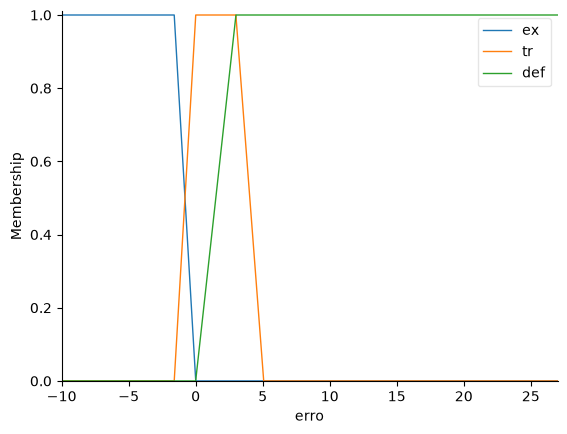

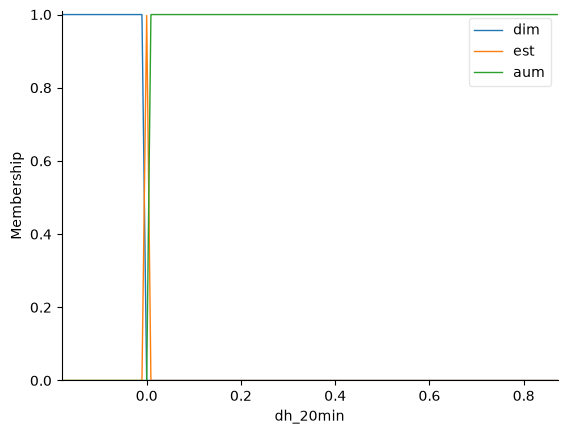

In [35]:
# Entrada erro
erro = ctrl.Antecedent(
    np.linspace(-10, 27, 4701),
    "erro"
)

erro["ex"] = fuzz.trapmf(
    erro.universe, [-10, -10, -1.60, 0]
)

erro["tr"] = fuzz.trapmf(
    erro.universe, [-1.60, 0, 3, 5.07]
)

erro["def"] = fuzz.trapmf(
    erro.universe, [0, 3, 27, 27]
)

# Entrada variação média da umidade
dh = ctrl.Antecedent(
    np.linspace(-0.18050, 0.8720, 3196),
    "dh_20min"
)

dh["dim"] = fuzz.trapmf(
    dh.universe, [-0.18050, -0.18050, -0.010, 0]
)

dh["est"] = fuzz.trimf(
    dh.universe, [-0.010, 0, 0.009]
)

dh["aum"] = fuzz.trapmf(
    dh.universe, [0, 0.009, 0.8720, 0.8720]
)

erro.view()
dh.view()

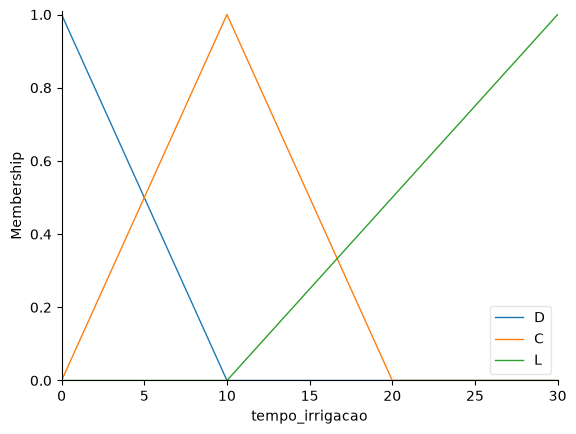

In [36]:
ti = ctrl.Consequent( # tem que avaliar depois com a bomba física
    np.linspace(0, 30, 301),
    "tempo_irrigacao"
)

# desligado
ti["D"] = fuzz.trimf(
    ti.universe, [0, 0, 10]
)

# ligado tempo curto
ti["C"] = fuzz.trimf(
    ti.universe, [0, 10, 20]
)

# ligado tempo longo
ti["L"] = fuzz.trimf(
    ti.universe, [10, 30, 30]
)

ti.view()

### regras

In [33]:
regra1 = ctrl.Rule(erro['ex'] & dh['dim'], ti['D'])
regra2 = ctrl.Rule(erro['ex'] & dh['est'], ti['D'])
regra3 = ctrl.Rule(erro['ex'] & dh['aum'], ti['D'])

regra4 = ctrl.Rule(erro['tr'] & dh['dim'], ti['D'])
regra5 = ctrl.Rule(erro['tr'] & dh['est'], ti['D'])
regra6 = ctrl.Rule(erro['tr'] & dh['aum'], ti['D'])

regra7 = ctrl.Rule(erro['def'] & dh['dim'], ti['L'])
regra8 = ctrl.Rule(erro['def'] & dh['est'], ti['L'])
regra9 = ctrl.Rule(erro['def'] & dh['aum'], ti['C'])

regras = [
    regra1, regra2, regra3,
    regra4, regra5, regra6, 
    regra7, regra8, regra9,
]

## SIMULANDO

## REMOÇÃO OUTLIERS

In [28]:
# from src.utils.pca import pca, t2_q, remove_anomalias_t2_q
# from sklearn.model_selection import train_test_split

# seed = 42

# def outlier_iqr(
#     df: pd.DataFrame,
#     columns: list | None = None,
#     show: bool = True,
#     remove: bool = False
# ):
#     if columns is None:
#         columns = df.columns

#     df_iqr = df.copy()

#     contagem_por_coluna = {}
#     mask_remover = pd.Series(False, index=df_iqr.index)

#     for column in columns:
#         q1 = df_iqr[column].quantile(0.25)
#         q3 = df_iqr[column].quantile(0.75)

#         iqr = q3 - q1

#         lower = q1 - 1.5 * iqr
#         upper = q3 + 1.5 * iqr

#         mask_outlier = (
#             (df_iqr[column] < lower) |
#             (df_iqr[column] > upper)
#         )

#         outlier_num = mask_outlier.sum()

#         contagem_por_coluna[column] = outlier_num
#         mask_remover |= mask_outlier

#         if show:
#             print(
#                 f"Quantidade de outliers da coluna "
#                 f"{column}: {outlier_num}"
#             )

#     idx_removidos = df_iqr.index[mask_remover]

#     if remove:
#         df_iqr = df_iqr.loc[~mask_remover].copy()

#     return df_iqr, idx_removidos, contagem_por_coluna

# def clean_anormaly(df, PARAMS, cols_meta, cols_target, flag_pca: bool = True, cutoff: str = None, save_flag: bool =  False, sufix_file = "none", name_dir = "none" ):
#     cols_features = [c for c in df.columns if c not in cols_meta + cols_target]

#     # treino e teste
#     if cutoff is None:
#         train_idx, test_idx = train_test_split(df.index, test_size=0.3, random_state=seed, shuffle=False)
#     # sem split temporal por enquanto...

#     train_df = df.loc[train_idx, cols_meta + cols_features + cols_target]
#     df_test  = df.loc[test_idx,  cols_meta + cols_features + cols_target]

#     # iqr
#     train_df, idx_removidos_iqr, contagem_por_coluna = outlier_iqr(
#         train_df.copy(),
#         PARAMS,
#         remove=True,
#         show=False
#     )

#     ## REMOVENDO AUSENTES!!!
#     train_df = train_df.dropna()

#     print("\n================ IQR ================")
#     print(f"Total de linhas removidas pelo IQR: {len(idx_removidos_iqr)}")

#     print("\nColunas responsáveis pela remoção:")

#     for col, qtd in contagem_por_coluna.items():
#         if qtd > 0:
#             print(f"{col}: {qtd} valores fora do IQR")

#     if flag_pca:
#         X_train = train_df[PARAMS]
#         meta_train = train_df[cols_meta]
#         cols_restantes = train_df.columns.difference(PARAMS + cols_meta).tolist()
#         y_train = train_df[cols_restantes]

#         # aplicando pca
#         vals, vecs, scaler, Z_train = pca(X_train=X_train)

#         # aplicando t2q
#         res = t2_q(Z_train, vals, vecs, k=3, name_IMG=sufix_file)

#         # removendo anomalias t2q
#         X_train_clean, y_train_clean, meta_train_clean = remove_anomalias_t2_q(X_train, y_train, res, meta_train)
#         train_df = pd.concat([meta_train_clean, X_train_clean, y_train_clean], axis=1)

#     # if save_flag:
#     #     save_file(train_df, name=f"train_{sufix_file}", name_dir=name_dir)
#     #     save_file(df_test, name=f"test_{sufix_file}", name_dir=name_dir)

#     return train_df, df_test


In [29]:
# PARAMS = [
#     'humidity_soil',
#     'temperature_env',
#     'humidity_env',
# ]

# cols_meta = ['ts_generation']
# cols_target = ['t_pi']

# clean_anormaly(df_aut, PARAMS=PARAMS, cols_meta=cols_meta, cols_target=cols_target)

In [30]:
# import matplotlib.pyplot as plt
# df_aut_t = df_aut.copy()

# # # quando humidity_soil != 0:
# df_aut_t["date"] = pd.to_datetime(df_aut_t["ts_generation"], unit="ms")
# mask = df_aut_t["humidity_soil"].ne(0.0)
# date = df_aut_t.loc[mask, "date"].iloc[0]

# print(date)
# df_aut_t = df_aut_t[df_aut_t["date"] > date]

# # # plt.plot(df_aut_t["humidity_soil"])
# plt.boxplot(df_aut_t["humidity_soil"])
# plt.show()

# # tendencia
# df_aut_t["tend"] = df_aut_t["humidity_soil"] - df_aut_t["humidity_soil_3"]
# # df_aut_t.head(5)

# plt.hist(df_aut_t["tend"])
# # plt.xlim(-5,5)
# plt.show()

MODEL